# Урок 1. Что такое Gaussian Splatting и какую задачу он решает

[План курса](../../README_ru.md) · [English](../en/lesson-01.ipynb) · [Следующий урок: одна гауссиана на прямой](lesson-02.ipynb)

Ты снимаешь предмет с нескольких сторон. Теперь хочется рассмотреть его с точки, в которой камера **не стояла**. Как получить такую картинку?

В этом уроке сначала покрутим небольшую сцену и заглянем внутрь её представления. Затем разберём путь от фотографий до результата. К концу ты сможешь объяснить:

- чем фотография отличается от представления сцены;
- что хранится в одной гауссиане и зачем их много;
- чем обучение отличается от просмотра готовой модели;
- почему новый ракурс ещё не означает знание невидимой стороны предмета.

Здесь не нужно заранее знать матрицы или производные. Сначала нам нужны наблюдения. Математический разбор одного мягкого пятна начинается в уроке 2.

## 1. Сначала посмотрим

Ниже — **учебная синтетическая сцена**: цветной шар над плоскостью. В ней 192 гауссианы: 128 на шаре и 64 на плоскости. Их положения, формы и цвета заданы программой вручную. Эта сцена **не обучалась по фотографиям**.

Для первых опытов используется ортографическая камера: параллельные направления проецирования позволяют рассматривать форму без перспективного уменьшения вдали. Это упрощённый учебный просмотрщик; перспективную камеру и полноценный рендеринг разберём позже. Порядок перекрытий определяется глубиной центров, поэтому при сложных пересечениях это приближение может ошибаться.

Если читаешь на GitHub, статические картинки уже показывают основные состояния. Для ползунков открой этот notebook в Jupyter по [инструкции запуска](../../README_ru.md) и выполни ячейки по порядку. Команда **Run All** запускает все ячейки. Первый блок находит папку курса и подключает инструменты визуализации; изучать его устройство сейчас не требуется.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
from IPython.display import display

course_root = next(
    (folder for folder in [Path.cwd(), *Path.cwd().parents]
     if (folder / "course_demos.py").is_file()),
    None,
)
if course_root is None:
    raise FileNotFoundError(
        "Открой этот notebook внутри скачанной папки курса."
    )
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))

from course_demos import scene_overview, scene_lab, coverage_figure, pipeline_figure
LANG = "ru"

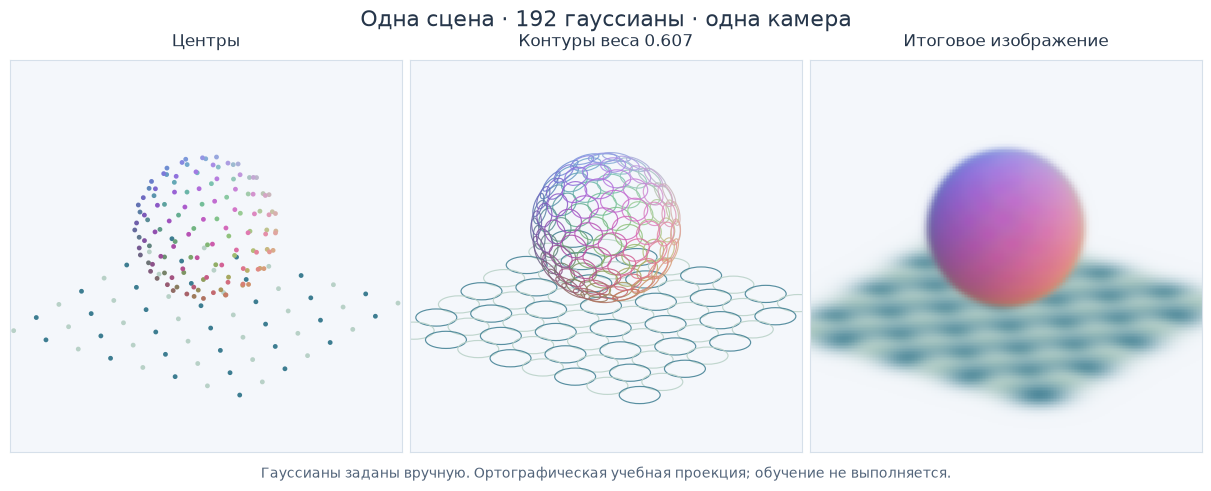

In [2]:
display(scene_overview(language=LANG))

Три картинки показывают **одни и те же данные с одного ракурса**:

| Режим | Что показано | На что смотреть |
|---|---|---|
| **Центры** | Только положение каждой гауссианы | Между отдельными точками остаются промежутки. Размер и мягкость пятна пока не показаны. |
| **Контуры** | Линия выбранного уровня влияния каждой гауссианы | Видны размер и ориентация. Это не твёрдая граница: влияние продолжается и за линией. |
| **Итоговое изображение** | Мягкие цветные пятна с перекрытиями | Несколько элементов вместе дают более цельное изображение. |

Контур в этом просмотрщике проходит там, где вес пятна составляет примерно **61% его веса в центре**. Число выбрано одинаково для всех гауссиан, чтобы сравнивать их форму. Откуда берётся вес и как его считать, разберём в следующем уроке.

Центры не исчезают из модели при переключении в режим итогового изображения. Меняется только способ показать один и тот же набор чисел.

In [3]:
display(scene_lab(language=LANG))

## 2. Пять опытов перед объяснением

Сначала попробуй предсказать результат. Затем измени управление и сравни с ожиданием.

1. **Переключи три режима, сохраняя ракурс.** Найди участок плоскости, где в режиме центров видны промежутки. Посмотри, что происходит с ним в режиме итогового изображения. Пятна не добавляют новые центры — они распределяют влияние вокруг уже существующих.
2. **Измени «Поворот камеры» и «Высота взгляда».** Первый ползунок перемещает камеру вокруг сцены, а второй меняет направление наблюдения сверху или сбоку. Плоскость с одного направления выглядит широкой, с другого — узкой. Это изменение изображения при взгляде на ту же сцену.
3. **Выбери одну гауссиану по индексу и включи изоляцию.** Индекс — просто номер элемента в списке. Сам по себе он не означает «стул», «стена» или «шар». Посмотри на выбранный элемент в режиме контуров, затем в режиме итогового изображения.
4. **Меняй непрозрачность выбранной гауссианы.** В режиме итогового изображения сравни значения 0, примерно 0.5 и 1. При нуле её цветовой вклад пропадает. При увеличении значения она сильнее влияет на изображение. В режиме центров маркер остаётся: он показывает наличие элемента в данных, а не его видимый вклад.
5. **Выключи изоляцию и нажми сброс.** Один изменённый элемент может быть почти незаметен среди остальных. Сброс вернёт исходные параметры и ракурс, чтобы сравнение можно было повторить.

**Что важно заметить:** при движении камеры программа не создаёт новую сцену заново. Она вычисляет другой вид того же набора элементов. В этом опыте обучение вообще не выполняется.

## 3. Какую задачу мы решаем

Фотография — это плоская сетка цветных пикселей. Пиксель сообщает цвет в конкретном месте **этого изображения**. Он не содержит готовый ответ на вопрос, что увидит камера после шага влево.

**Представление сцены** хранит данные, из которых можно вычислять изображения для разных камер. **Рендеринг** — само вычисление изображения по этим данным и выбранной камере. **Синтез нового ракурса** — получение изображения с положения камеры, которого не было среди исходных снимков.

Представь кружку на столе. На снимке спереди видна ручка справа. После обхода стола ручка может оказаться слева или скрыться за корпусом. Простое растягивание исходной фотографии не знает, как должны измениться перекрытия и что скрывается за предметом.

Gaussian Splatting хранит сцену как набор управляемых гауссиан. Из них рендерер собирает изображение для выбранного ракурса. При реконструкции параметры этого набора подбираются так, чтобы виды из исходных камер были похожи на исходные фотографии.

Но «похоже на фотографии» и «точная модель всей физической сцены» — разные требования. Пока запомним это различие: оно объяснит ограничения в разделе про невидимые стороны.

## 4. Что хранит одна гауссиана

Удобная первая аналогия — мягкое пятно краски: у него есть место, размер, цвет и сила вклада. В 3D это пространственное распределение влияния, которое при проекции даёт пятно на экране. Это **не капля жидкости и не твёрдая оболочка**: аналогия помогает представить мягкость, но не задаёт физику материала.

Подписи «Шар» и «Плоскость» в карточке выбранного элемента заданы автором учебной сцены вручную. Они не означают, что алгоритм сам распознал эти объекты.

Разберём четыре группы свойств. Числа ниже — отдельные простые примеры, а не значения выбранного элемента в просмотрщике.

### Позиция: где находится центр

В плоскости нужны два числа, в пространстве — три. Например, позиция **(0, 0, 1)** в системе координат нашего опыта означает: нулевое смещение по двум направлениям плоскости и высота 1 над ней. Здесь вертикальное направление называется **z**. В других программах соглашение об осях может отличаться. Единица координат здесь условная: она не обязана означать метр.

Центр — место наибольшего веса гауссианы. Изменение позиции переносит всё распределение вместе с ним.

### Форма: насколько широко и в каких направлениях распределено влияние

Сравни шарик и сплющенный воздушный шарик. У второго влияние может быть широким вдоль поверхности и узким поперёк неё. Поворот меняет направления вытягивания.

Например, масштабы **(0.2, 0.2, 0.2)** задают одинаковый масштаб по трём собственным направлениям. Если первый увеличить до **0.4**, распределение станет шире в этом направлении. Эти числа не задают жёсткую внешнюю границу: влияние плавно ослабевает, а не обрывается.

В уроке 2 разберём смысл одного масштаба на прямой. Затем построим форму на плоскости и только после этого вернёмся к пространственному случаю.

### Цвет: какой вклад вносит элемент

В простом примере используются три компоненты **RGB**: красная, зелёная и синяя. При диапазоне от 0 до 1 цвет **(1, 0, 0)** — красный, **(0, 1, 0)** — зелёный, **(1, 1, 1)** — белый.

В нашей учебной сцене цвет каждого элемента постоянен. В полноценном 3DGS цвет может зависеть от направления взгляда: это помогает описывать изменение видимого цвета при обходе блестящих объектов. Такой способ задания цвета отдельно разберём в уроке 15.

### Непрозрачность: насколько сильно элемент влияет на изображение

Параметр непрозрачности находится между **0 и 1**. При 0 элемент не вносит цветового вклада; при больших значениях его вклад сильнее.

Важно: значение **1 не превращает всё пятно в непрозрачную пластинку**. Влияние меняется по пятну: в центре оно сильнее, дальше от центра слабее. Итог зависит также от других элементов и порядка перекрытий.

Здесь мы используем слово **непрозрачность**, потому что увеличение параметра усиливает вклад. Если назвать его прозрачностью, направление действия окажется перепутанным.

## 5. Зачем много элементов

Одна гауссиана даёт мягкий вклад. Несколько правильно размещённых элементов могут совместно описать цветовой переход, край или участок поверхности. В нашей сцене шар состоит из многих элементов, но ни один из них сам по себе не знает, что он «часть шара».

Сравни два утверждения:

- **«Добавили больше элементов».** У модели стало больше параметров, которыми можно описывать изображение.
- **«Изображение стало точнее».** Это результат удачного размещения и настройки этих параметров, достаточных наблюдений и работы алгоритма обучения.

Первое не гарантирует второе. Миллион случайно расставленных гауссиан не превращается автоматически в точную комнату. И фиксированного числа, после которого любая сцена становится фотореалистичной, нет.

Изолируй один элемент, затем верни всю сцену. Этот опыт показывает совместный вклад элементов. Он ещё **не показывает**, как обучение найдёт нужные положения и формы: это задача следующего блока курса.

## 6. От фотографий до готовой модели

В нашем просмотрщике параметры уже заданы. При реконструкции реальной сцены их ещё предстоит найти. Для базового процесса с фотографиями полезно различать следующие этапы.

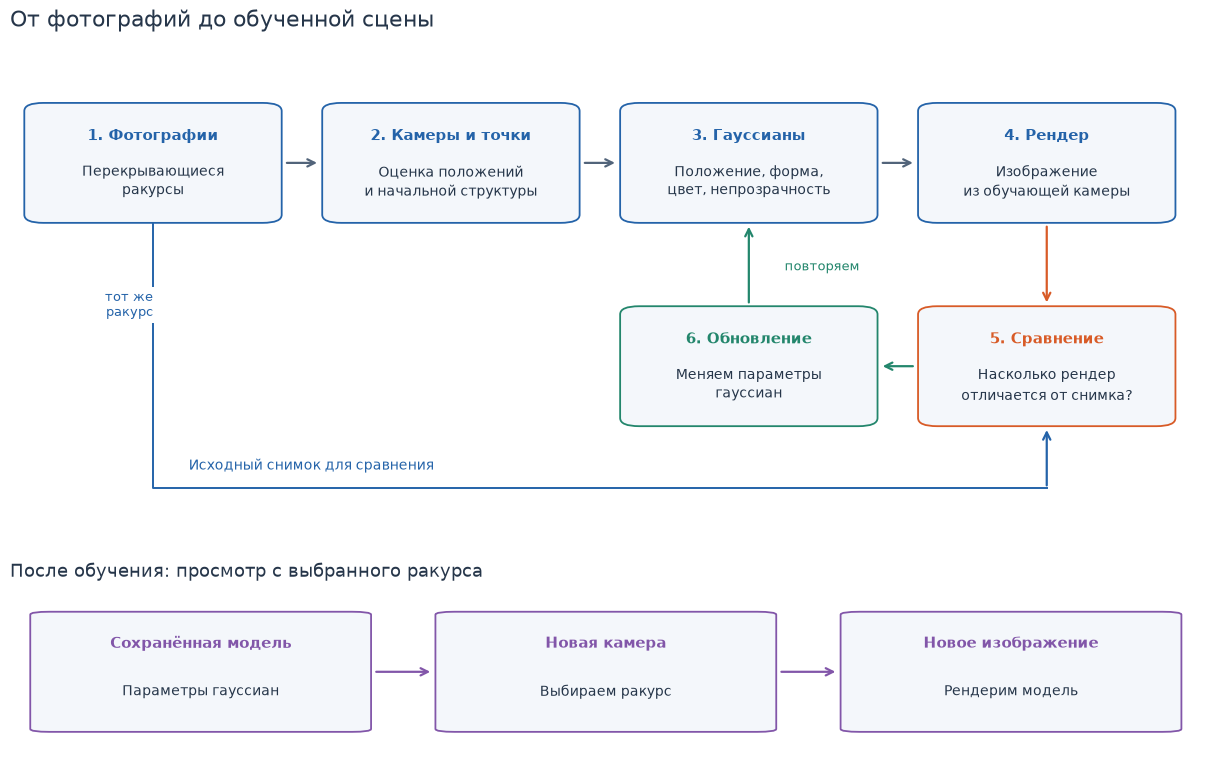

In [4]:
display(pipeline_figure(language=LANG))

| Этап | Что приходит на вход | Что получается |
|---|---|---|
| **Съёмка** | Неподвижная сцена и камера | Перекрывающиеся фотографии с разных положений |
| **Восстановление камер и точек** | Фотографии с общими видимыми деталями | Оценки параметров камер и разреженное облако точек; часто для этого используют COLMAP |
| **Инициализация гауссиан** | Начальные точки и связанная информация | Первоначальный набор гауссиан |
| **Обучение** | Гауссианы, камеры и исходные изображения | Параметры, при которых рендеры лучше согласуются с фотографиями |
| **Просмотр** | Сохранённая модель и выбранная камера | Изображение с нужного ракурса |

Положения камер здесь тоже являются результатом оценки, а не волшебно известными данными. Ошибки их восстановления могут мешать последующему обучению.

### Что происходит внутри обучения

Представь одну исходную фотографию. Мы ставим виртуальную камеру в соответствующее положение и рендерим текущую модель. Затем сравниваем результат с фотографией: где цвет совпал, где объект сдвинут, где не хватает деталей.

После этого алгоритм изменяет параметры, чтобы уменьшить выбранную меру ошибки. Берётся следующий ракурс, сравнение повторяется. В базовом 3DGS во время обучения также добавляются и удаляются гауссианы. Изменение их числа и настройка параметров — связанные, но разные операции.

На этом этапе достаточно понимать **что сравнивается и что изменяется**. В уроках 6–9 мы сами измерим ошибку и пройдём один шаг обновления на числах. Полное обучение 3D-сцены и изменение числа элементов появятся в уроках 16–17.

### Обучение и просмотр — разные работы

При обучении нужны исходные изображения и многократные сравнения. При обычном просмотре сохранённой модели рендерер вычисляет очередной кадр по уже найденным параметрам. Поэтому время обучения и скорость просмотра нужно оценивать отдельно.

В [результатах оригинальной работы 3DGS](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/) можно посмотреть реальные реконструкции и сравнения с эталонными изображениями. Это отдельный пример применения метода; локальные шар и плоскость выше остаются вручную заданной учебной сценой.

**Дополнительный опыт с реальной реконструкцией (нужен интернет).** Открой раздел Visual Comparisons на странице работы. Сопоставь результат Ours и эталон Ground Truth для одного ракурса. Найди одну деталь, которая совпала, и одно заметное отличие: край, мелкую текстуру или блик. Эталонная картинка служит для сравнения; не нужно считать, что именно этот кадр участвовал в обучении. Этот опыт дополняет локальную практику, но для выполнения урока не обязателен.

## 7. Новый ракурс и невидимая сторона — разные вещи

Посмотрим на схему сверху. Камеры наблюдают объект с разных направлений. Схема показывает только видимость: она **не моделирует обучение и не доказывает качество реконструкции**.

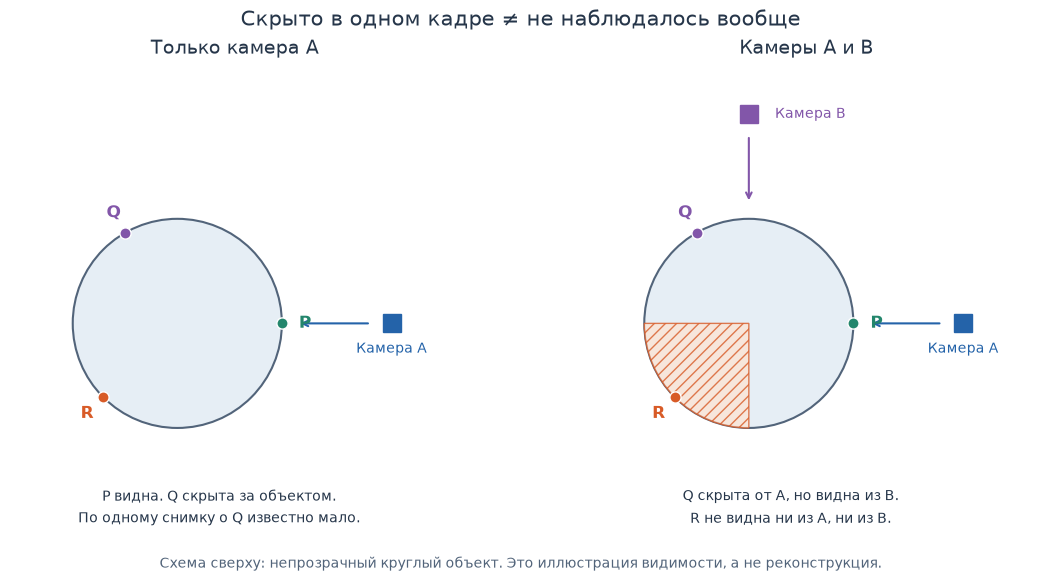

In [5]:
display(coverage_figure(language=LANG))

Здесь есть три ситуации:

1. **Участок виден камере A.** Изображение A содержит наблюдение этого участка.
2. **Участок скрыт от A, но виден камере B.** Одна фотография не даёт всей информации, но другая может её дополнить.
3. **Участок скрыт от обеих камер.** В этих наблюдениях нет прямого свидетельства о его внешнем виде.

Конкретный пример: у двух коробок одинаковые передние стороны. Задняя сторона первой красная, второй синяя. Если все фотографии показывают только переднюю сторону и нигде не отражают заднюю, эти фотографии сами по себе не сообщают, какой цвет сзади.

Алгоритм может выдать какой-то результат, но это ещё не подтверждённое восстановление скрытой стороны. Чтобы проверить её, нужны дополнительные наблюдения или предположения, которые добавляют информацию извне.

Это не означает, что каждый новый ракурс плох. Новый ракурс может показывать поверхность, которую уже хорошо наблюдали на других снимках. Проблема начинается там, где данных недостаточно или они противоречивы.

Вручную заданный шар в нашем опыте известен программе со всех сторон. Поэтому свободный обход этого шара **не доказывает**, что метод научился восстанавливать никогда не снятые поверхности.

## 8. Чем это отличается от других представлений

Теперь сравнение можно привязать к знакомому вопросу: **что хранится и как из этого получается изображение?**

| Представление | Что хранится | Что полезно помнить |
|---|---|---|
| **Полигональная сетка — mesh** | Вершины и грани, обычно вместе с материалами или текстурами | Удобна для явной поверхности, редактирования и взаимодействия. Может быть создана художником или восстановлена из изображений. |
| **Воксели** | Значения в ячейках трёхмерной сетки | Простой способ хранить пространственные данные. Плотная сетка быстро растёт при повышении разрешения; существуют разреженные представления. |
| **Облако точек** | Координаты точек и, возможно, цвет и другие свойства | Полезно для измерений и как начальная геометрическая информация. Способ отображения точек — отдельный выбор. |
| **NeRF и родственные методы** | В исходном NeRF плотность зависит от положения, а цвет — также от направления взгляда | В исходном NeRF используется нейросеть; другие методы меняют представление и вычисления. Скорость зависит от конкретного метода и реализации. |
| **Gaussian Splatting** | Набор гауссиан с настраиваемыми параметрами | Явные элементы проецируются и смешиваются. Можно исследовать отдельный элемент, но его связь с целым объектом не задаётся автоматически. |

У каждой строки есть варианты и ограничения. Например, [Instant-NGP](https://nvlabs.github.io/instant-ngp/) показывает, почему фраза «любой NeRF всегда медленный» не подходит для всего семейства методов.

Оригинальная работа 3DGS показала сочетание высокого качества и быстрого рендеринга в своих экспериментах. Это не обещание одинакового качества или частоты кадров на любом компьютере и любой сцене. На результат влияют данные, реализация, разрешение изображения и количество работы на кадр.

Для этого курса главное преимущество явного набора гауссиан — возможность **посмотреть на элементы и связать изменение их параметров с изображением**. Этим и будем пользоваться при изучении.

## 9. Проверь понимание

Сначала ответь своими словами. Затем открой разбор. Если ответ расходится с ожиданием, вернись к соответствующему опыту.

### Задание 1. Что поменял переключатель?

Ты переключил «Центры» на «Итоговое изображение», не изменяя камеру. В изображении стало меньше видимых промежутков. Добавились ли новые точки в данные?

<details>
<summary>Разбор</summary>

Нет. Используется тот же набор из 192 элементов. В режиме центров показана только позиция каждого. В режиме итогового изображения рендерер использует также форму, цвет и непрозрачность, поэтому вклад распределяется вокруг центров и перекрывается. Изменилось отображение данных, а не количество элементов.

</details>

### Задание 2. Почему элемент исчезает не во всех режимах?

Изолируй гауссиану и установи её непрозрачность в 0. В режиме итогового изображения её цветовой вклад исчез. Почему в режиме центров всё ещё можно показывать точку?

<details>
<summary>Разбор</summary>

Параметр непрозрачности управляет вкладом в изображение. Он не удаляет запись об элементе из списка. Режим центров — диагностический вид данных: он может показывать позицию даже элемента с нулевым вкладом. Чтобы убрать запись, понадобилась бы отдельная операция удаления.

</details>

### Задание 3. Хватит ли фотографий спереди?

На всех снимках коробки видна только передняя сторона. Получившаяся модель показывает синюю заднюю сторону. Можно ли считать этот цвет восстановленным достоверно?

<details>
<summary>Разбор</summary>

Нет, если задняя сторона нигде не наблюдалась и дополнительных сведений о ней нет. Красная и синяя задние стороны могли бы дать те же самые исходные изображения. Нужно добавить наблюдение сзади или отдельно оговорить предположение о цвете. Сам факт, что рендерер умеет показать заднюю сторону, не доказывает правильность результата.

</details>

### Задание 4. Что нужно для следующего кадра?

Модель уже обучена и сохранена. Ты немного повернул камеру. Нужно ли снова подбирать все гауссианы по исходным фотографиям?

<details>
<summary>Разбор</summary>

При обычном просмотре — нет. Рендерер берёт сохранённые параметры и новую камеру, затем вычисляет изображение. Это новый кадр, но не новое обучение. Если модель плохо описывает нужный ракурс, вращение камеры само по себе не исправит её параметры.

</details>

### Задание 5. Больше элементов — всегда лучше?

В одну модель добавили тысячу случайных гауссиан. Обязательно ли она теперь точнее воспроизводит исходные фотографии?

<details>
<summary>Разбор</summary>

Нет. Новые элементы дают дополнительные параметры, но их нужно правильно настроить. Случайные положения и цвета могут ухудшить изображение и увеличить стоимость рендеринга. Улучшение надо проверять сравнением с наблюдениями, включая ракурсы, отложенные для проверки.

</details>

## 10. Что забираем с собой

- **Модель сцены** хранит параметры. **Рендерер** превращает их в изображение для выбранной камеры.
- Гауссиана имеет позицию, форму, цвет и непрозрачность. Мягкий вклад распределён вокруг центра.
- Одни и те же элементы можно показать как центры, контуры и итоговое изображение. Контур не является твёрдой границей.
- При реконструкции параметры подбираются по наблюдениям. При просмотре используется уже найденная модель.
- Данные с других ракурсов могут раскрыть скрытые участки. Для поверхности, которой нет ни в одном наблюдении, достоверного ответа может не быть.

Теперь у нас есть конкретный вопрос: **как описать мягкое уменьшение влияния от центра числами?** В [уроке 2](lesson-02.ipynb) начнём с прямой, построим колокол по отдельным операциям и вручную вычислим значение в выбранной точке.

## Источники и дополнительные примеры

- [Kerbl et al. — 3D Gaussian Splatting for Real-Time Radiance Field Rendering](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/): исходная работа, видео и сравнения результатов.
- [COLMAP — Tutorial](https://colmap.github.io/tutorial.html): восстановление камер и структуры по изображениям, рекомендации по съёмке.
- [Mildenhall et al. — NeRF](https://www.matthewtancik.com/nerf): исходное представление neural radiance fields.
- [Müller et al. — Instant-NGP](https://nvlabs.github.io/instant-ngp/): пример того, как изменение представления и реализации ускоряет нейронные графические методы.